# 05 - Modelo Cubist Regression

**Objetivo:** estimar `ORGC` (%) con Cubist usando directamente los archivos generados por `02_preprocesamiento.ipynb`.  
**Referencia:** Ou et al. (2024), *Environmental Sciences Europe* ([DOI](https://doi.org/10.1186/s12302-024-00912-x)).

**¿Cómo funciona Cubist?** Construye reglas que dividen las observaciones en regiones; dentro de cada región ajusta una regresión lineal. Combina varios modelos mediante **comités** y puede corregir predicciones con **vecinos cercanos**. En el artículo, Cubist superó a RF (R²: 0.292 frente a 0.263), con otros datos y predictores.

El notebook conserva la separación entrenamiento/prueba del grupo. La búsqueda de parámetros se hace solo con entrenamiento.

In [1]:
# Ejecutar una vez si no está instalada la librería.
%pip install "cubist>=1.2.2,<2"

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\Israel\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from cubist import Cubist
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold
from sklearn.metrics import mean_absolute_error

# Igual que en 02_modelos.ipynb: reutilizamos evaluación del módulo src.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from evaluation import evaluate_models

pd.set_option('display.float_format', '{:.4f}'.format)

## 1. Carga de datos

Se leen directamente los CSV **sin escalar** de `data/processed`. Cubist no necesita `StandardScaler`, por lo que no se repiten el EDA, la imputación ni la división del conjunto de datos.

In [3]:
RUTA = ROOT / 'data' / 'processed'
X_train = pd.read_csv(RUTA / 'X_train.csv')
X_test = pd.read_csv(RUTA / 'X_test.csv')
y_train = pd.read_csv(RUTA / 'y_train.csv')['ORGC']
y_test = pd.read_csv(RUTA / 'y_test.csv')['ORGC']

print('Entrenamiento:', X_train.shape, '| Prueba:', X_test.shape)
print('Variables:', list(X_train.columns))

Entrenamiento: (17338, 8) | Prueba: (4263, 8)
Variables: ['depth_mid', 'thickness', 'PHAQ', 'SILT', 'CLAY', 'TCEQ', 'ELCOSP', 'ECEC']


## 2. Validación cruzada y búsqueda de hiperparámetros

Se comparan **3 y 5 folds**. En cada uno, `GridSearchCV` prueba combinaciones de:
- `n_committees`: número de modelos de reglas que se combinan.
- `neighbors`: vecinos que corrigen la predicción; `None` desactiva la corrección.
- `n_rules`: límite máximo de reglas generadas.

**Importante:** los archivos procesados originales no incluyen el perfil de cada fila. Si existe `groups_train.csv` con `profile_code` alineado con `X_train.csv`, se usa `GroupKFold`; de lo contrario, se usa `KFold` normal. Este último no evita que capas de un mismo perfil coincidan entre entrenamiento y validación.

In [4]:
ARCHIVO_GRUPOS = RUTA / 'groups_train.csv'
grupos = None
if ARCHIVO_GRUPOS.exists():
    grupos = pd.read_csv(ARCHIVO_GRUPOS)['profile_code']
    if len(grupos) != len(X_train):
        raise ValueError('groups_train.csv debe tener una fila por cada fila de X_train.csv')

# Ajustar a True para la búsqueda corta inicial; False explora más combinaciones.
MODO_RAPIDO = True
PARAMETROS = {
    'n_committees': [1, 10] if MODO_RAPIDO else [1, 10, 100],
    'neighbors': [None, 5] if MODO_RAPIDO else [None, 5, 9],
    'n_rules': [100]
}
FOLDS = [3, 5]
print('Validación:', 'GroupKFold' if grupos is not None else 'KFold')

Validación: GroupKFold


In [5]:
busquedas = {}
for k in FOLDS:
    cv = GroupKFold(n_splits=k) if grupos is not None else KFold(
        n_splits=k, shuffle=True, random_state=42
    )
    busqueda = GridSearchCV(
        estimator=Cubist(random_state=42),
        param_grid=PARAMETROS,
        scoring='neg_root_mean_squared_error',
        cv=cv,
        n_jobs=1,
        refit=True
    )
    if grupos is not None:
        busqueda.fit(X_train, y_train, groups=grupos)
    else:
        busqueda.fit(X_train, y_train)
    busquedas[k] = busqueda
    print(f'{k} folds | RMSE CV: {-busqueda.best_score_:.4f} |', busqueda.best_params_)

3 folds | RMSE CV: 4.7485 | {'n_committees': 10, 'n_rules': 100, 'neighbors': 5}
5 folds | RMSE CV: 4.7399 | {'n_committees': 10, 'n_rules': 100, 'neighbors': 5}


In [6]:
# Comparamos las combinaciones evaluadas con 5 folds (criterio principal).
busqueda_5 = busquedas[5]
cv_resultados = pd.DataFrame(busqueda_5.cv_results_)
tabla_cv = cv_resultados[
    ['param_n_committees', 'param_neighbors', 'param_n_rules',
     'mean_test_score', 'std_test_score', 'rank_test_score']
].copy()
tabla_cv['RMSE_CV'] = -tabla_cv.pop('mean_test_score')
tabla_cv['DE_RMSE'] = tabla_cv.pop('std_test_score')
display(tabla_cv.sort_values('rank_test_score').round(4))

,param_n_committees,param_neighbors,param_n_rules,rank_test_score,RMSE_CV,DE_RMSE
3,10,5,100,1,4.7399,0.2699
2,10,None,100,2,4.7595,0.3798
0,1,None,100,3,4.7998,0.3541
1,1,5,100,4,4.8213,0.2284


## 3. Entrenamiento y evaluación

Se utiliza el mejor modelo seleccionado con **5 folds**. La función `evaluate_models()` del archivo `src/evaluation.py` calcula las métricas del entrenamiento y de prueba, igual que en el notebook de modelos del grupo. Los resultados están en la escala original de `ORGC` (%).

In [7]:
modelo_cubist = busqueda_5.best_estimator_
resultados = evaluate_models(
    {'Cubist': modelo_cubist}, X_train, y_train, X_test, y_test
)
display(resultados.pivot(
    index='Modelo', columns='Conjunto', values=['R2', 'RMSE', 'MAE']
))

R2          RMSE           MAE       
Conjunto   test  train   test  train   test  train
Modelo                                            
Cubist   0.2202 0.5962 4.8521 3.3741 1.6624 1.2387

## 4. Análisis de predicciones

Se comparan los valores observados y predichos sobre el conjunto de prueba. La línea diagonal representa una predicción perfecta; la separación de los puntos respecto a esa línea muestra los errores.

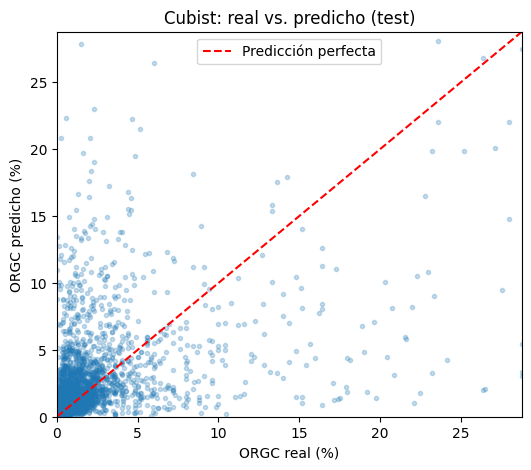

In [8]:
pred = modelo_cubist.predict(X_test)
limite = np.quantile(y_test, 0.99)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, pred, alpha=0.25, s=9)
ax.plot([0, limite], [0, limite], 'r--', label='Predicción perfecta')
ax.set(xlim=(0, limite), ylim=(0, limite),
       xlabel='ORGC real (%)', ylabel='ORGC predicho (%)',
       title='Cubist: real vs. predicho (test)')
ax.legend()
plt.show()

## 5. Reglas y conclusiones

`output_str` contiene las reglas y las regresiones locales generadas por Cubist (si la versión instalada de la librería lo expone). Se muestran las primeras líneas para que la salida no sea demasiado extensa.

In [9]:
reglas = getattr(modelo_cubist, 'output_str', None)
if reglas:
    print('\n'.join(reglas.splitlines()[:35]))
else:
    print('La versión instalada no expone las reglas en output_str.')

print('\nMejores hiperparámetros:', busqueda_5.best_params_)
print('RMSE CV (5 folds):', round(-busqueda_5.best_score_, 4))

La versión instalada no expone las reglas en output_str.

Mejores hiperparámetros: {'n_committees': 10, 'n_rules': 100, 'neighbors': 5}
RMSE CV (5 folds): 4.7399


### Interpretación

- **Cubist** combina reglas y regresiones lineales locales; los comités y vecinos modifican su complejidad y forma de predecir.
- **Validación cruzada:** se seleccionan hiperparámetros únicamente con los datos de entrenamiento. Variar el número de folds es una prueba de estabilidad de la evaluación, no un hiperparámetro de Cubist.
- **Conjunto de prueba:** se utiliza para medir la generalización una vez elegido el modelo.
- **Alcance:** los predictores disponibles en allpaDB no son iguales a los 17 del artículo. Los R² publicados allí no garantizan resultados semejantes aquí.

*Nota metodológica:* la imputación y el clipping fueron ajustados previamente por el grupo sobre todo `X_train`. Al realizar CV sobre estos CSV ya procesados, los folds no vuelven a ajustar esas transformaciones; esto podría introducir algo de optimismo en las métricas de CV.